In [52]:
import openseespy.opensees as ops
import opsvis as opsv
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [53]:
# unit conversion
m=1
mm=0.001*m
kn=1
pa=1
kpa=1000*pa
mpa=1000*kpa
gpa=1000*mpa

In [54]:
ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 3)

In [55]:
# define steel material
mattag=1
fy=350*mpa
E=200*gpa
b=0.001
ops.uniaxialMaterial('Steel02', mattag, fy, E, b)

In [56]:
# define concrete material
fpc=-30*mpa
epsc0=-0.002
fpcu=-20*mpa
epsu=-0.008
lamda=0.1
ft=3*mpa
ets=150*mpa
ops.uniaxialMaterial('Concrete02', 2, fpc, epsc0, fpcu, epsu, lamda, ft, ets)
ops.uniaxialMaterial('Concrete02',3,
                     -25*mpa,
                     -0.002,
                     -15*mpa,
                     -0.006,
                     0.1,
                     2*mpa,
                     100*mpa)

ops.node(1, 0.0,0.0)
ops.node(2, 0.0,1)
ops.node(3, 0.0,2)
ops.node(4, 0.0,3)
ops.fix(1, 1, 1, 1)

In [57]:
# def getsection():
#section defination
# Bd=400*mm
# D=600*mm
confinedconcretetag=2
unconfinedconcretetag=3
numsubdiv=10
sectag=1
ops.section('Fiber', sectag, '-GJ', 1.0e6)
ops.patch('rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2) #CONFINED CONCRETE

ops.patch('quad',unconfinedconcretetag,1,1,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2) #unconfined concrete
ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2) #unconfined concrete
ops.layer('straight', mattag, 3,300*mm**2,450*mm/2,300*mm/2,450*mm/2,-300*mm/2) #steel layer
ops.layer('straight', mattag, 3,300*mm**2,-450*mm/2,300*mm/2,-450*mm/2,-300*mm/2) #steel layer

In [58]:
#geometry transformation
ops.geomTransf('PDelta', 1)
ops.beamIntegration('Lobatto', 1, sectag, 2)
mass=6000

ops.element('forceBeamColumn', 1, 1, 2, 1, 1,'-mass',mass) #ops.element('forceBeamColumn', eleTag, iNode, jNode, transfTag, integrationTag, '-mass', massDensity)
ops.element('forceBeamColumn', 2, 2, 3, 1, 1,'-mass',mass)
ops.element('forceBeamColumn', 3, 3, 4, 1, 1,'-mass',mass)

In [59]:
# def plot():
fib_sec_1 = [
    ['section', 'Fiber', 1, '-GJ', 1.0e6],
    ['patch','rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2],
    ['patch','quad',unconfinedconcretetag,1,2,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2],   # right cover (यो थपियो)
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2],  # top cover
    ['patch','quad',unconfinedconcretetag,1,2,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2], # left cover
    ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2], # bottom cover
    ['layer', 'straight', mattag, 3, 300*mm**2, 450*mm/2,300*mm/2,450*mm/2,-300*mm/2],
    ['layer', 'straight', mattag, 3, 300*mm**2, -450*mm/2,300*mm/2,-450*mm/2,-300*mm/2]
]

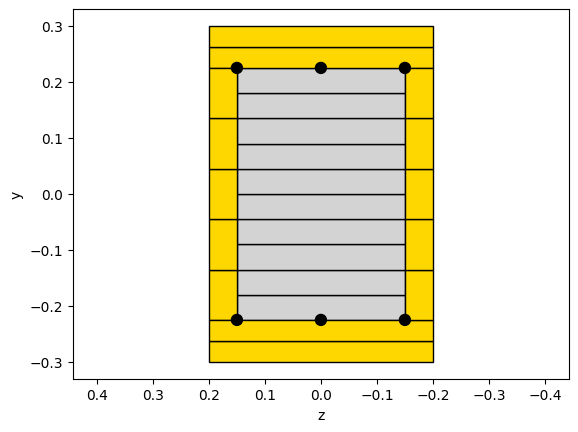

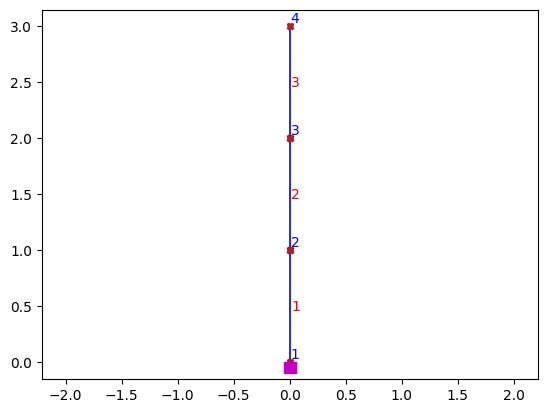

In [60]:
matcolor = ['r', 'lightgrey', 'gold', 'w', 'w', 'w']
opsv.plot_fiber_section(fib_sec_1, matcolor=matcolor)
plt.axis('equal')
opsv.plot_model()
plt.show()


In [61]:
#Load analysis 
px=1*kn
delx=0.0001*m

In [62]:
def loadcontrolforce(numstep):

    #time series tag 
    linearSeriesTag=1
    patterntag=2
    ops.timeSeries('Linear', linearSeriesTag)
    ops.pattern('Plain', patterntag, linearSeriesTag)
    ops.load(4, px, 0.0, 0.0)

    #analysis commands
    ops.system("BandGeneral")
    ops.numberer("Plain")
    ops.constraints("Transformation")
    #integrator('LoadControl', incr, numIter=1, minIncr=incr, maxIncr=incr)
    ops.integrator('LoadControl', 1)
    ops.algorithm("Newton")
    ops.analysis("Static")

    #ops.test('NormDispIncr', tol, iter, pFlag=0, nType=2)
    ops.test('NormDispIncr', 1.0e-6, 200)

    #Recorders
    ops.recorder('Node', '-file', 'loadcontrolforce_disp.txt', '-time', '-node', 4, '-dof', 1,2,3,'disp')
    ops.recorder('Node', '-file', 'loadcontrolforce_reaction.txt', '-time', '-node', 1, '-dof', 1,2,3,'reaction')

    ops.record()
    for i in range(200000):
        status=ops.analyze(1)
        if status!= 0:
            status=BasicAnalysisLoop(status)
            if status!= 0:
                print("Analysis failed at load factor ", i+1)
                break

In [63]:
def BasicAnalysisLoop(status):
    if status != 0:
        print("Trying 10 times smaller timestep at load factor ", )
        ops.integrator('LoadControl', 0.1)
        status = ops.analyze(1)
    if status != 0:
        print("Trying 100 times smaller timestep at load factor ", )
        ops.integrator('LoadControl', 0.01)
        status = ops.analyze(1)
    if status != 0:
        print("Trying with 200 iterations at load factor ", )
        ops.test('NormDispIncr', 1.0e-4, 500)
        status = ops.analyze(1)
    if status != 0:
        print("Trying Modified Newton's Algorithm at load factor ", )
        ops.algorithm('ModifiedNewton')
        ops.integrator('LoadControl', 1)
        status = ops.analyze(1)  

    #reverting back to original state of analysis parameters for returning to normal analysis
    ops.algorithm('Newton')
    ops.integrator('LoadControl', 1)
    ops.test('NormDispIncr', 1.0e-6, 200)

    return status

after: 200 iterations  current Norm: 3.16454e-06 (max: 1e-06, Norm deltaR: 20.8339)
NewtonRaphson::solveCurrentStep() -the ConvergenceTest object failed in test()
StaticAnalysis::analyze() - the Algorithm failed at step: 0 with domain at load factor 79524
OpenSees > analyze failed, returned: -3 error flag
after: 200 iterations  current Norm: 2.66508e-06 (max: 1e-06, Norm deltaR: 9.49143)
NewtonRaphson::solveCurrentStep() -the ConvergenceTest object failed in test()
StaticAnalysis::analyze() - the Algorithm failed at step: 0 with domain at load factor 79524.1
OpenSees > analyze failed, returned: -3 error flag
after: 200 iterations  current Norm: 6.15709e-06 (max: 1e-06, Norm deltaR: 97.0183)
NewtonRaphson::solveCurrentStep() -the ConvergenceTest object failed in test()
StaticAnalysis::analyze() - the Algorithm failed at step: 0 with domain at load factor 79524.2
OpenSees > analyze failed, returned: -3 error flag
after: 200 iterations  current Norm: 7.73087e-06 (max: 1e-06, Norm deltaR: 

Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 10 times smaller timestep at load factor 
Trying 100 times smaller timestep at load factor 
Trying with 200 iterations at load factor 
Trying 10 times smaller timestep at load factor 
Trying 100 times smaller timestep at load factor 
Trying with 200 iterations at load factor 
Trying 10 times smaller timestep at load factor 
Trying 100 times smaller timestep at load factor 
Trying with 200 iterations at load factor 
Trying 10 times smaller timestep at load factor 
Trying 100 times smaller timestep at load factor 
Trying with 200 iterations at load

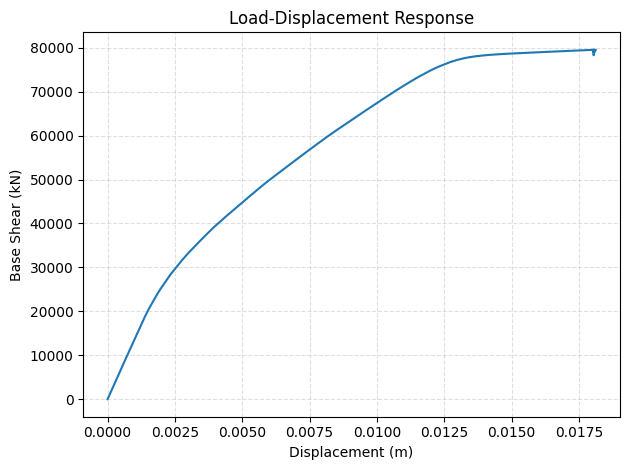

In [64]:
loadcontrolforce(2000000)


# --- Load data ---
displacements = np.loadtxt('loadcontrolforce_disp.txt', delimiter=" ")
reactions = np.loadtxt('loadcontrolforce_reaction.txt', delimiter=" ")
disp_x = displacements[:, 1]
base_shear = -reactions[:, 1]

# --- CSV file 
df = pd.DataFrame({
    'Displacement (m)': disp_x,
    'Base Shear (kN)': base_shear
})
df.to_csv('pushover_results.csv', index=False)
print("Saved: pushover_results.csv")

# --- Plot ---
fig, ax = plt.subplots()
ax.plot(disp_x, base_shear)
ax.set_xlabel('Displacement (m)')
ax.set_ylabel('Base Shear (kN)')
ax.set_title('Load-Displacement Response')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [65]:
def dsp():
    # unit conversion
    m=1
    mm=0.001*m
    kn=1
    pa=1
    kpa=1000*pa
    mpa=1000*kpa
    gpa=1000*mpa

    ops.wipe()
    ops.model('basic', '-ndm', 2, '-ndf', 3)
    # define steel material
    mattag=1
    fy=350*mpa
    E=200*gpa
    b=0.001
    ops.uniaxialMaterial('Steel02', mattag, fy, E, b)
    # define concrete material
    fpc=-30*mpa
    epsc0=-0.002
    fpcu=-20*mpa
    epsu=-0.008
    lamda=0.1
    ft=3*mpa
    ets=150*mpa
    ops.uniaxialMaterial('Concrete02', 2, fpc, epsc0, fpcu, epsu, lamda, ft, ets)
    ops.uniaxialMaterial('Concrete02',3,
                        -25*mpa,
                        -0.002,
                        -15*mpa,
                        -0.006,
                        0.1,
                        2*mpa,
                        100*mpa)

    ops.node(1, 0.0,0.0)
    ops.node(2, 0.0,1)
    ops.node(3, 0.0,2)
    ops.node(4, 0.0,3)
    ops.fix(1, 1, 1, 1)
    confinedconcretetag=2
    unconfinedconcretetag=3
    numsubdiv=10
    sectag=1
    ops.section('Fiber', sectag, '-GJ', 1.0e6)
    ops.patch('rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2) #CONFINED CONCRETE

    ops.patch('quad',unconfinedconcretetag,1,1,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2) #unconfined concrete
    ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2) #unconfined concrete
    ops.patch('quad',unconfinedconcretetag,1,1,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2) #unconfined concrete
    ops.patch('quad',unconfinedconcretetag,1,1,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2) #unconfined concrete
    ops.layer('straight', mattag, 3,300*mm**2,450*mm/2,300*mm/2,450*mm/2,-300*mm/2) #steel layer
    ops.layer('straight', mattag, 3,300*mm**2,-450*mm/2,300*mm/2,-450*mm/2,-300*mm/2) #steel layer

            #geometry transformation
    ops.geomTransf('PDelta', 1)
    ops.beamIntegration('Lobatto', 1, sectag, 2)
    mass=6000

    ops.element('forceBeamColumn', 1, 1, 2, 1, 1,'-mass',mass) #ops.element('forceBeamColumn', eleTag, iNode, jNode, transfTag, integrationTag, '-mass', massDensity)
    ops.element('forceBeamColumn', 2, 2, 3, 1, 1,'-mass',mass)
    ops.element('forceBeamColumn', 3, 3, 4, 1, 1,'-mass',mass)
    # def plot():
    fib_sec_1 = [
        ['section', 'Fiber', 1, '-GJ', 1.0e6],
        ['patch','rect',confinedconcretetag,numsubdiv,1,-450*mm/2,-300*mm/2,450*mm/2,300*mm/2],
        ['patch','quad',unconfinedconcretetag,1,2,450*mm/2,400*mm/2,450*mm/2,-400*mm/2,600*mm/2,-400*mm/2,600*mm/2,400*mm/2],   # right cover (यो थपियो)
        ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,400*mm/2,-450*mm/2,300*mm/2,450*mm/2,300*mm/2,450*mm/2,400*mm/2],  # top cover
        ['patch','quad',unconfinedconcretetag,1,2,-600*mm/2,400*mm/2,-600*mm/2,-400*mm/2,-450*mm/2,-400*mm/2,-450*mm/2,400*mm/2], # left cover
        ['patch','quad',unconfinedconcretetag,1,5,-450*mm/2,-300*mm/2,-450*mm/2,-400*mm/2,450*mm/2,-400*mm/2,450*mm/2,-300*mm/2], # bottom cover
        ['layer', 'straight', mattag, 3, 300*mm**2, 450*mm/2,300*mm/2,450*mm/2,-300*mm/2],
        ['layer', 'straight', mattag, 3, 300*mm**2, -450*mm/2,300*mm/2,-450*mm/2,-300*mm/2]
        ]
    
    

In [66]:
def dispControlForce_Pushover(NumSteps):
    dsp()
    controlNode = 4
    controlNodeDof = 1
    linearSeriesTag = 3
    #time series
    ops.timeSeries('Linear',linearSeriesTag)

    #load pattern
    ops.pattern('Plain',4, linearSeriesTag)
    #now instead of using load at control node, we use sp command single point constraint
    ops.load(controlNode, *[1, 0.0, 0.0])
    #xxx ops.sp(controlNode, controlNodeDof, DEL_x)xxxx

    #analysis commands
    ops.constraints("Transformation")
    ops.numberer("Plain")
    ops.system("BandGeneral")
    ops.algorithm("Newton")
    #integrator('DisplacementControl', nodeTag, dof, incr, numIter=1, dUmin=incr, dUmax=incr)
    ops.integrator('DisplacementControl', controlNode, controlNodeDof, delx)
    #ops.test('NormDispIncr', tol, iter, pFlag=0, nType=2)
    ops.test('NormDispIncr', 1.0e-6, 50)
    ops.analysis("Static")

    #recorder('Node', '-file', filename, , '-timeSeries', tsTag, '-time','-closeOnWrite', '-node', *nodeTags=[],'-dof', *dofs=[], respType)
    ops.recorder('Node', '-file', "displacements.txt",'-closeOnWrite', '-time', '-node', *[4], '-dof', *[1,2,3], 'disp')
    ops.recorder('Node', '-file', "reactions.txt", '-closeOnWrite', '-time', '-node', *[1], '-dof', *[1,2,3], 'reaction')
    
    #analyze(numIncr=1, dt=0.0, dtMin=0.0, dtMax=0.0, Jd=0)
    ops.record()
    status = ops.analyze(NumSteps)
    # return status

In [67]:
dispControlForce_Pushover(2000)

Saved: pushover_results.csv


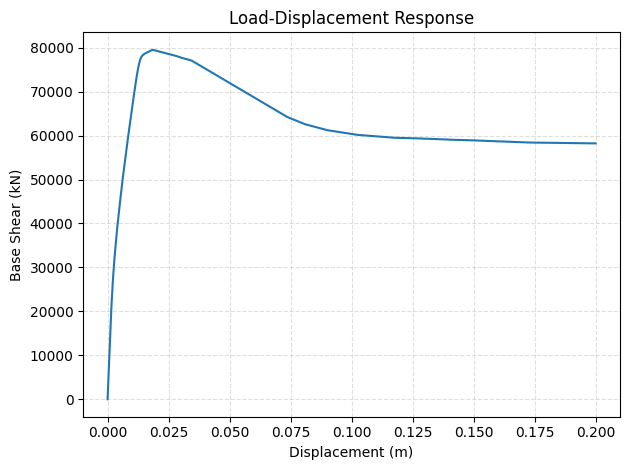

In [68]:
# --- Load data ---
displacements = np.loadtxt('displacements.txt', delimiter=" ")
reactions = np.loadtxt('reactions.txt', delimiter=" ")
disp_x = displacements[:, 1]
base_shear = -reactions[:, 1]

# --- CSV file 
df = pd.DataFrame({
    'Displacement (m)': disp_x,
    'Base Shear (kN)': base_shear
})
df.to_csv('pushover_results.csv', index=False)
print("Saved: pushover_results.csv")

# --- Plot ---
fig, ax = plt.subplots()
ax.plot(disp_x, base_shear)
ax.set_xlabel('Displacement (m)')
ax.set_ylabel('Base Shear (kN)')
ax.set_title('Load-Displacement Response')
ax.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()
